# Board Games Market Intelligence

## Resumen ejecutivo

Este proyecto analiza el catálogo de BoardGameGeek para ayudar a una editorial a priorizar prototipos antes de invertir en producción. El flujo integra y limpia 21.831 registros de valoraciones y 21.631 registros de detalles, identifica 200 IDs sin correspondencia, conserva 21.475 juegos con al menos 30 valoraciones y crea variables de diseño comparables.

Se estudian seis preguntas: qué vocabularios aparecen en las descripciones, cómo se relacionan complejidad y adopción, cómo evolucionó el mercado, dónde aparecen oportunidades editoriales, qué perfiles de producto existen y cuánto puede anticiparse la recepción crítica con atributos previos al lanzamiento.

El análisis encuentra tres perfiles de producto, seleccionados con silhouette score, y muestra que el diseño aporta una señal predictiva pero no explica todo el desempeño. Gradient Boosting alcanza $R^2 = 0.283$ y MAE = 0.179; Random Forest obtiene ROC-AUC = 0.831 y Average Precision = 0.473 para ordenar el top 15% de valoraciones.

La conclusión es prudente: estos resultados sirven para reducir incertidumbre y priorizar investigación, no para garantizar ventas. Precio, arte, componentes, marketing, distribución y público objetivo quedan fuera de los datos.

## Criterios de preparación

La integración usa un inner join por `id`: los 200 registros sin correspondencia no tienen todos los metadatos necesarios para analizar diseño y no se completan con información inventada. Se conserva el nombre canónico de `details.csv` y se consolida el año con el valor válido más antiguo.

Los valores de jugadores se convierten a numéricos, se corrigen cuando están invertidos, se reemplazan ceros mínimos y se marcan valores de `maxplayers` superiores a 20 como atípicos antes de limitarlos para el análisis de perfiles. Las duraciones cero se estiman con `minplaytime` y `maxplaytime`; las duraciones superiores a 720 minutos se excluyen del análisis comercial.

Se conservan los juegos históricos con `es_historico = True`, se imputan años inválidos con la mediana válida y se convierten las columnas de listas mediante `ast.literal_eval`, que permite parsearlas sin ejecutar código. El umbral `users_rated >= 30` reduce la inestabilidad de juegos con muestras diminutas.

Estas reglas no eliminan automáticamente información incómoda: cada exclusión, corrección o variable derivada queda visible en el dataset y se explica antes de interpretar los gráficos.

In [2]:
import pandas as pd

URL_BASE = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-25/"

valoraciones = pd.read_csv(URL_BASE + "ratings.csv")
detalles = pd.read_csv(URL_BASE + "details.csv")

print(f"Valoraciones: {valoraciones.shape[0]:,} registros")
print(f"Detalles: {detalles.shape[0]:,} registros")


Valoraciones: 21,831 registros
Detalles: 21,631 registros


In [3]:
import ast
import numpy as np


MAX_JUGADORES_ANALISIS = 20


def parsear_lista_segura(valor):
    """Convierte una lista serializada en una lista de strings sin ejecutar código."""
    if not isinstance(valor, str) or pd.isna(valor):
        return []
    try:
        resultado = ast.literal_eval(valor)
    except (ValueError, SyntaxError):
        return []
    return [item for item in resultado if isinstance(item, str)] if isinstance(resultado, list) else []


def integrar_fuentes(valoraciones, detalles):
    """Integra ambas fuentes y conserva la primera fecha de publicación válida."""
    ids_valoraciones = set(valoraciones["id"])
    ids_detalles = set(detalles["id"])
    discrepancias = ids_valoraciones.symmetric_difference(ids_detalles)
    print(f"IDs solo en una fuente: {len(discrepancias):,}")

    ratings = valoraciones.drop(columns=["num", "name"], errors="ignore")
    details = detalles.drop(columns=["num"], errors="ignore")
    integrado = pd.merge(ratings, details, on="id", how="inner")
    integrado = integrado.rename(columns={"primary": "name"})

    year_ratings = pd.to_numeric(integrado["year"], errors="coerce")
    year_details = pd.to_numeric(integrado["yearpublished"], errors="coerce")
    integrado["year_consolidated"] = np.where(
        (year_ratings > 0) & (year_details > 0),
        np.minimum(year_ratings, year_details),
        np.where(year_ratings > 0, year_ratings, year_details),
    )
    return integrado.drop(columns=["year", "yearpublished"])


def sanear_jugadores_y_duracion(df, max_duracion=720):
    """Corrige valores físicos y marca valores extremos antes del análisis."""
    result = df.copy()
    numeric_columns = ["minplayers", "maxplayers", "playingtime", "minplaytime", "maxplaytime"]
    for column in numeric_columns:
        result[column] = pd.to_numeric(result[column], errors="coerce")
    result["playingtime"] = result["playingtime"].astype(float)

    inverted = result["minplayers"] > result["maxplayers"]
    result.loc[inverted, ["minplayers", "maxplayers"]] = result.loc[
        inverted, ["maxplayers", "minplayers"]
    ].values
    result["minplayers"] = result["minplayers"].replace(0, 1).fillna(1)
    result["maxplayers"] = np.where(
        result["maxplayers"].isna() | (result["maxplayers"] <= 0),
        result["minplayers"],
        result["maxplayers"],
    )
    result["maxplayers_atipico"] = result["maxplayers"] > MAX_JUGADORES_ANALISIS
    result["maxplayers"] = result["maxplayers"].clip(upper=MAX_JUGADORES_ANALISIS)

    invalid_duration = result["playingtime"] <= 0
    estimated_duration = (result["minplaytime"] + result["maxplaytime"]) / 2
    result.loc[invalid_duration, "playingtime"] = np.where(
        estimated_duration[invalid_duration] > 0,
        estimated_duration[invalid_duration],
        np.nan,
    )
    result["playingtime"] = result["playingtime"].fillna(result["playingtime"].median())
    return result[result["playingtime"] <= max_duracion].copy()


def categorizar_y_sanear_anios(df):
    """Conserva juegos históricos y reemplaza años inválidos por la mediana."""
    result = df.copy()
    result["year_consolidated"] = pd.to_numeric(result["year_consolidated"], errors="coerce")
    result["es_historico"] = result["year_consolidated"] < 1900
    invalid_year = result["year_consolidated"].isna() | (result["year_consolidated"] <= 0)
    median_year = result.loc[~invalid_year, "year_consolidated"].median()
    result.loc[invalid_year, "year_consolidated"] = median_year
    return result


def preparar_dataset(valoraciones, detalles, min_votos=30):
    """Construye el dataset analítico final y sus variables de densidad."""
    integrado = integrar_fuentes(valoraciones, detalles)
    filtrado = integrado[integrado["users_rated"] >= min_votos].copy()
    limpio = categorizar_y_sanear_anios(sanear_jugadores_y_duracion(filtrado))
    list_columns = [
        "boardgamecategory",
        "boardgamemechanic",
        "boardgamedesigner",
        "boardgameartist",
        "boardgamepublisher",
    ]
    for column in list_columns:
        parsed_column = f"{column}_parsed"
        limpio[parsed_column] = limpio[column].apply(parsear_lista_segura) if column in limpio else [[] for _ in range(len(limpio))]
    limpio["num_mecanicas"] = limpio["boardgamemechanic_parsed"].str.len()
    limpio["num_categorias"] = limpio["boardgamecategory_parsed"].str.len()
    return limpio.reset_index(drop=True)


df = preparar_dataset(valoraciones, detalles, min_votos=30)
print(f"Dataset analítico: {df.shape[0]:,} juegos y {df.shape[1]} variables")
print(f"Valores de maxplayers limitados para análisis: {int(df['maxplayers_atipico'].sum())}")


IDs solo en una fuente: 200
Dataset analítico: 21,475 juegos y 37 variables
Valores de maxplayers limitados para análisis: 271


## Preguntas de investigación

El análisis se formula como una secuencia de decisiones editoriales. Las preguntas describen asociaciones y capacidad de priorización; no pretenden demostrar causalidad.

1. **Lenguaje del catálogo:** ¿Qué temas y vocabularios aparecen en las descripciones mediante TF-IDF + NMF?
2. **Adopción:** ¿Cómo se relacionan la cantidad de mecánicas, la duración y el volumen de juegos registrados en colecciones?
3. **Evolución:** ¿Cómo cambian la valoración y la densidad mecánica de los títulos publicados entre 1990 y 2021?
4. **Oportunidad:** ¿Qué juegos combinan recepción crítica alta con una demanda relativa todavía no satisfecha?
5. **Perfiles:** ¿Qué arquetipos de producto emergen al agrupar atributos de diseño y qué tamaño tiene cada segmento?
6. **Predicción:** ¿Cuánto puede anticiparse la recepción crítica usando solo atributos disponibles antes del lanzamiento?

El notebook separa tres capas: descripción del mercado, priorización de oportunidades y evaluación predictiva. Esta separación evita presentar una correlación exploratoria como una recomendación automática de producción.

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

PALETTE = {
    "ink": "#243447",
    "muted": "#5B6B7A",
    "blue": "#2F6690",
    "teal": "#3C8D8A",
    "orange": "#D9822B",
    "red": "#B54747",
    "sand": "#F4EFE6",
    "light_blue": "#E7F0F7",
    "light_teal": "#E7F3F1",
    "light_orange": "#FFF1DE",
}
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list(
    "board_games_market",
    [PALETTE["sand"], PALETTE["teal"], PALETTE["blue"]],
)


def configurar_estilo():
    """Define una identidad visual única y legible para el informe."""
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({
        "figure.dpi": 120,
        "font.family": "DejaVu Sans",
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "axes.labelcolor": PALETTE["ink"],
        "xtick.color": PALETTE["muted"],
        "ytick.color": PALETTE["muted"],
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })


def graficar_topicos_vs_rating(data):
    order = data.groupby("topico_nombre")["bayes_average"].median().sort_values(ascending=False).index
    figure, axis = plt.subplots(figsize=(10, 5.5))
    sns.boxplot(data=data, x="bayes_average", y="topico_nombre", order=order, color=PALETTE["blue"], fliersize=2, ax=axis)
    median = data["bayes_average"].median()
    axis.axvline(median, color=PALETTE["orange"], linestyle="--", linewidth=1.5, label=f"Mediana del mercado: {median:.2f}")
    axis.set_title("¿Qué temas se asocian con una mejor recepción crítica?")
    axis.set_xlabel("Calificación bayesiana, escala 1 a 10")
    axis.set_ylabel("")
    axis.legend(frameon=False, loc="lower right")
    sns.despine(ax=axis, left=True)
    figure.tight_layout()
    return figure


def graficar_complejidad_adopcion(data):
    figure, axis = plt.subplots(figsize=(9.5, 5.5))
    points = axis.scatter(data["num_mecanicas"], data["playingtime"], c=data["owned"], cmap=SEQUENTIAL_CMAP, alpha=0.58, s=28, linewidth=0)
    axis.set_yscale("log")
    colorbar = figure.colorbar(points, ax=axis, pad=0.02)
    colorbar.set_label("Copias registradas en colecciones")
    axis.set_title("La profundidad del diseño compite con el tiempo disponible")
    axis.set_xlabel("Cantidad de mecánicas")
    axis.set_ylabel("Duración estimada, minutos (escala logarítmica)")
    axis.text(0.01, -0.23, "Cada punto representa un juego; la escala logarítmica permite comparar duraciones extremas.", transform=axis.transAxes, color=PALETTE["muted"], fontsize=9)
    sns.despine(ax=axis)
    figure.tight_layout()
    return figure


def graficar_evolucion_mercado(data):
    evolution = data.groupby("year_consolidated").agg(rating_medio=("bayes_average", "mean"), mecanicas_medias=("num_mecanicas", "mean")).reset_index()
    figure, rating_axis = plt.subplots(figsize=(10, 5.5))
    mechanics_axis = rating_axis.twinx()
    rating_axis.plot(evolution["year_consolidated"], evolution["rating_medio"], color=PALETTE["blue"], linewidth=2.4, label="Rating medio")
    mechanics_axis.plot(evolution["year_consolidated"], evolution["mecanicas_medias"], color=PALETTE["orange"], linewidth=2.4, linestyle="--", label="Mecánicas medias")
    rating_axis.set_title("El mercado combina valoración y diseños más densos")
    rating_axis.set_xlabel("Año de publicación")
    rating_axis.set_ylabel("Rating bayesiano medio", color=PALETTE["blue"])
    mechanics_axis.set_ylabel("Mecánicas medias por juego", color=PALETTE["orange"])
    lines = rating_axis.lines + mechanics_axis.lines
    rating_axis.legend(lines, [line.get_label() for line in lines], frameon=False, loc="upper left")
    rating_axis.grid(axis="x", visible=False)
    figure.tight_layout()
    return figure


def graficar_matriz_oportunidad(data):
    working = data[["bayes_average", "tasa_deseo"]].dropna()
    x_cut = working["bayes_average"].median()
    y_cut = working["tasa_deseo"].median()
    y_max = working["tasa_deseo"].quantile(0.99)
    x_min = working["bayes_average"].min() - 0.2
    x_max = working["bayes_average"].max() + 0.2
    figure, axis = plt.subplots(figsize=(11, 6.5))
    axis.axvspan(x_cut, x_max, y_cut / y_max, 1, color=PALETTE["light_teal"], alpha=0.9)
    axis.axvspan(x_cut, x_max, 0, y_cut / y_max, color=PALETTE["light_blue"], alpha=0.9)
    axis.axvspan(x_min, x_cut, y_cut / y_max, 1, color=PALETTE["light_orange"], alpha=0.9)
    axis.scatter(working["bayes_average"], working["tasa_deseo"], color=PALETTE["ink"], alpha=0.28, s=20, linewidth=0)
    axis.axvline(x_cut, color=PALETTE["muted"], linestyle="--", linewidth=1)
    axis.axhline(y_cut, color=PALETTE["muted"], linestyle="--", linewidth=1)
    axis.text(x_max, y_max * 0.94, "OPORTUNIDAD\ncalidad + demanda", ha="right", va="top", color=PALETTE["teal"], weight="bold")
    axis.text(x_max, y_max * 0.06, "CATÁLOGO CONSOLIDADO", ha="right", va="bottom", color=PALETTE["blue"], weight="bold")
    axis.text(x_min, y_max * 0.94, "HYPE A VALIDAR", ha="left", va="top", color=PALETTE["orange"], weight="bold")
    axis.set_xlim(x_min, x_max)
    axis.set_ylim(0, y_max)
    axis.set_title("Matriz editorial: calidad crítica frente a demanda insatisfecha")
    axis.set_xlabel(f"Rating bayesiano (mediana: {x_cut:.2f})")
    axis.set_ylabel(f"Usuarios que desean / usuarios que poseen (mediana: {y_cut:.2f})")
    sns.despine(ax=axis)
    figure.tight_layout()
    return figure


configurar_estilo()


In [5]:
import html
import re
from nltk.corpus import stopwords
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer


def limpiar_texto_descripcion(texto):
    """Elimina HTML, caracteres no informativos y espacios redundantes."""
    if not isinstance(texto, str) or pd.isna(texto):
        return ""
    texto_limpio = html.unescape(texto)
    texto_limpio = re.sub(r"<[^>]+>", " ", texto_limpio)
    texto_limpio = re.sub(r"[^a-zA-Z\s]", " ", texto_limpio)
    return re.sub(r"\s+", " ", texto_limpio).strip().lower()


df["desc_limpia"] = df["description"].apply(limpiar_texto_descripcion)
stop_words = list(stopwords.words("english")) + [
    "game", "games", "player", "players", "play", "played", "playing",
    "board", "card", "cards", "turn", "points", "rule", "rules", "win",
]
vectorizador_tfidf = TfidfVectorizer(
    max_df=0.85,
    min_df=5,
    max_features=2500,
    stop_words=stop_words,
    ngram_range=(1, 2),
)
matriz_tfidf = vectorizador_tfidf.fit_transform(df["desc_limpia"])
nmf_model = NMF(n_components=5, random_state=42, init="nndsvda", max_iter=500)
matriz_topicos = nmf_model.fit_transform(matriz_tfidf)
df["topico_dominante"] = matriz_topicos.argmax(axis=1)

nombres_topicos = {
    0: "Gestión urbana y construcción",
    1: "Estrategia militar y guerra",
    2: "Cartas, rondas y objetivos",
    3: "Dados y azar",
    4: "Losetas y puntuación",
}
df["topico_nombre"] = df["topico_dominante"].map(nombres_topicos)
palabras = vectorizador_tfidf.get_feature_names_out()
topicos_vocabulario = {
    f"Topico_{indice}": [palabras[posicion] for posicion in componente.argsort()[::-1][:10]]
    for indice, componente in enumerate(nmf_model.components_)
}
print("Tópicos extraídos:")
for nombre, palabras_topico in topicos_vocabulario.items():
    print(f"{nombre}: {', '.join(palabras_topico[:6])}")


Tópicos extraídos:
Topico_0: new, city, world, build, publisher, description
Topico_1: war, units, battle, map, combat, counters
Topico_2: one, hand, round, number, two, wins
Topico_3: dice, roll, die, roll dice, rolling, rolls
Topico_4: tiles, tile, place, placed, score, one


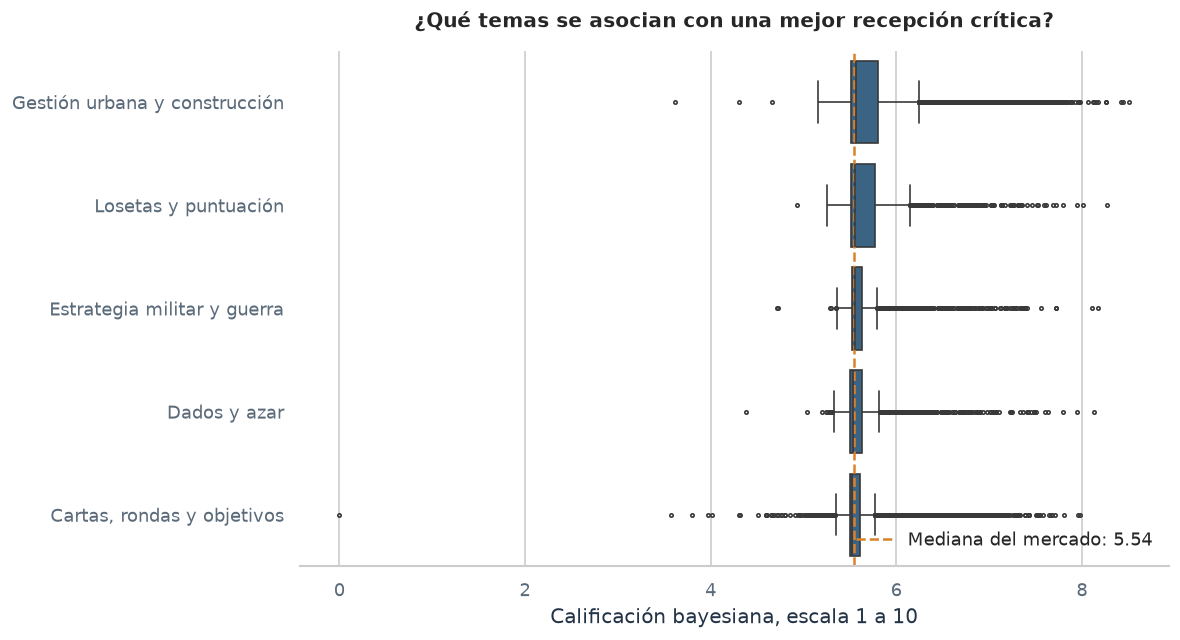

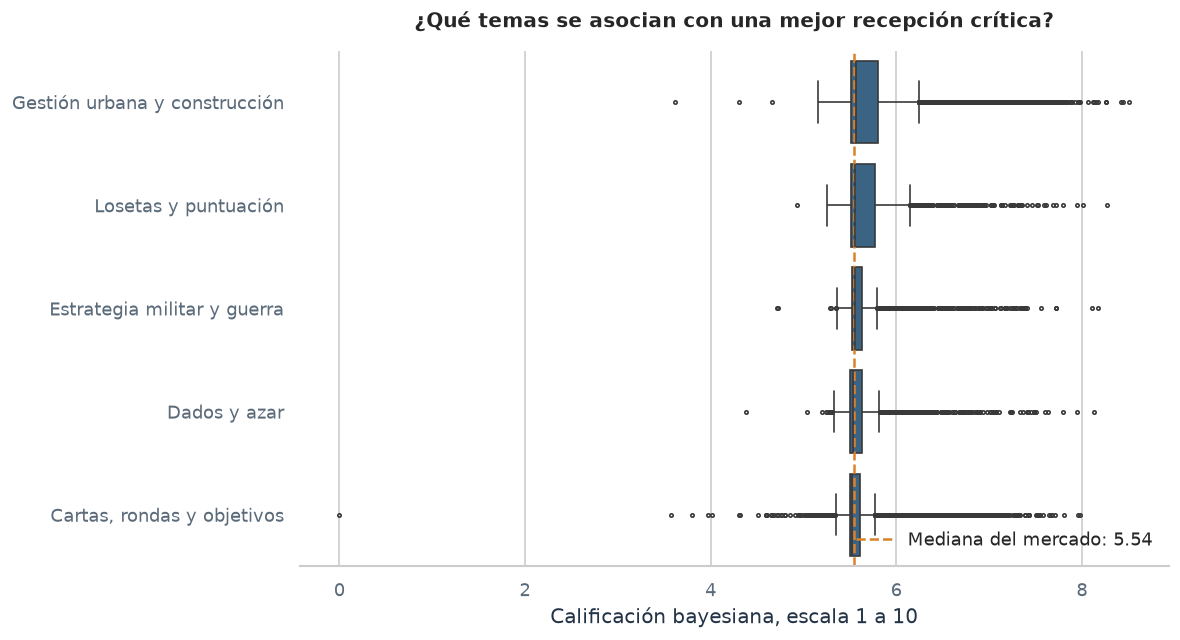

In [6]:
figura_topicos = graficar_topicos_vs_rating(df)
figura_topicos


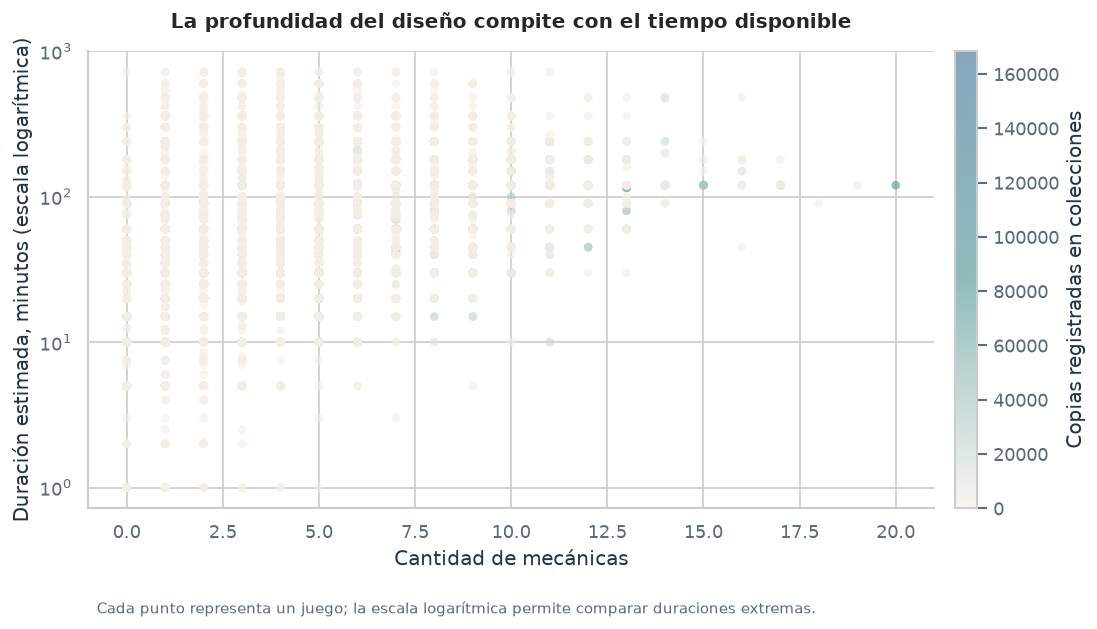

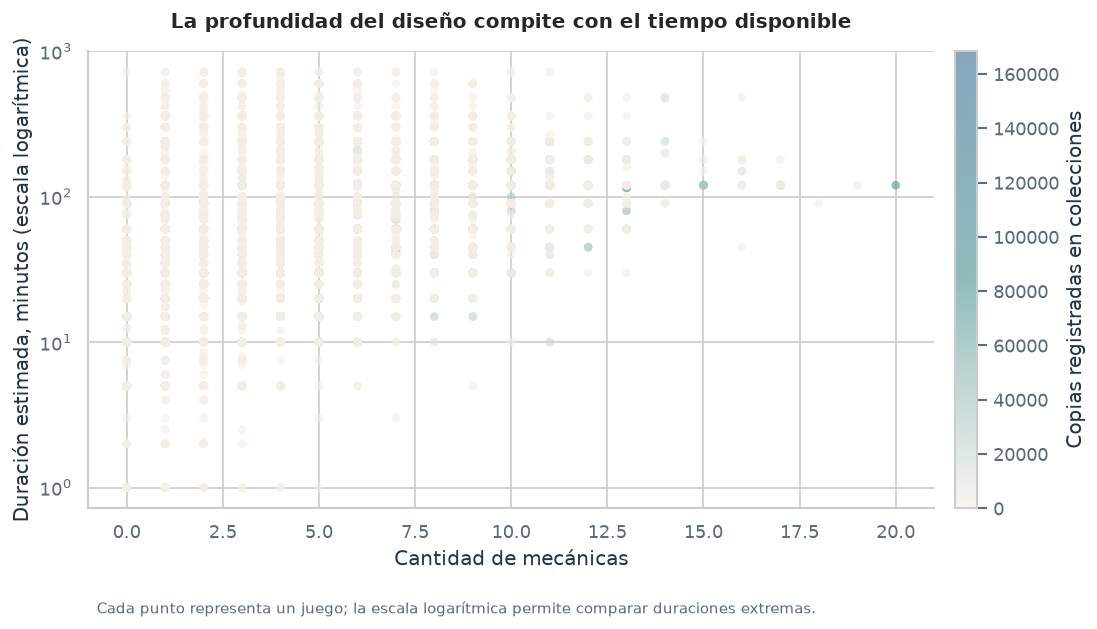

In [7]:
figura_complejidad = graficar_complejidad_adopcion(df)
figura_complejidad


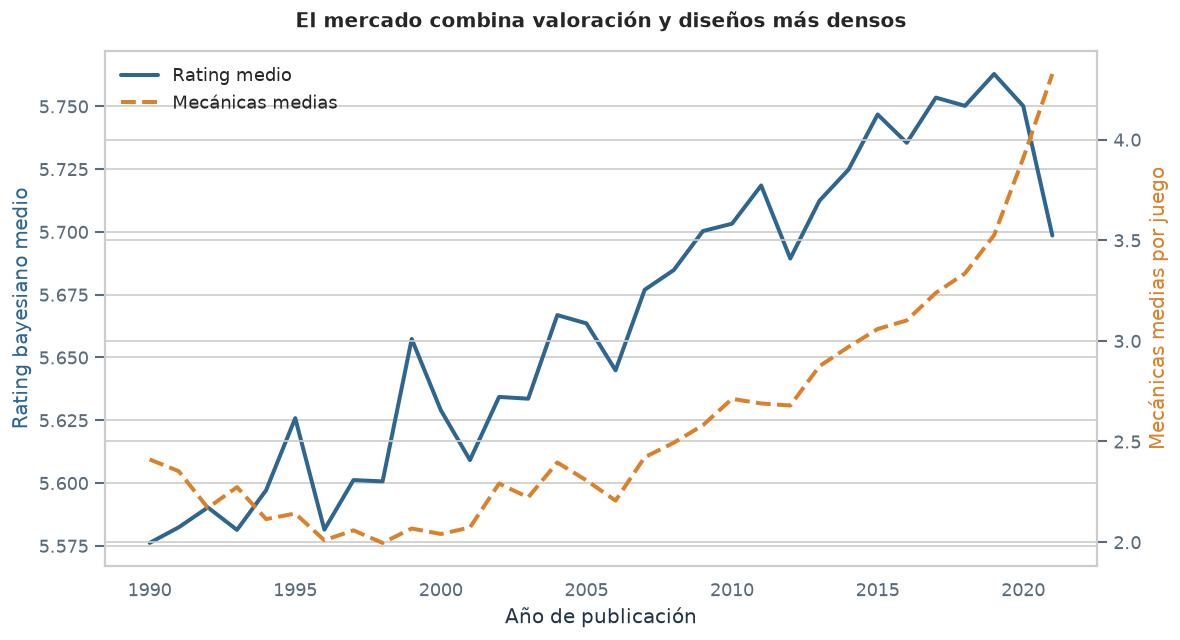

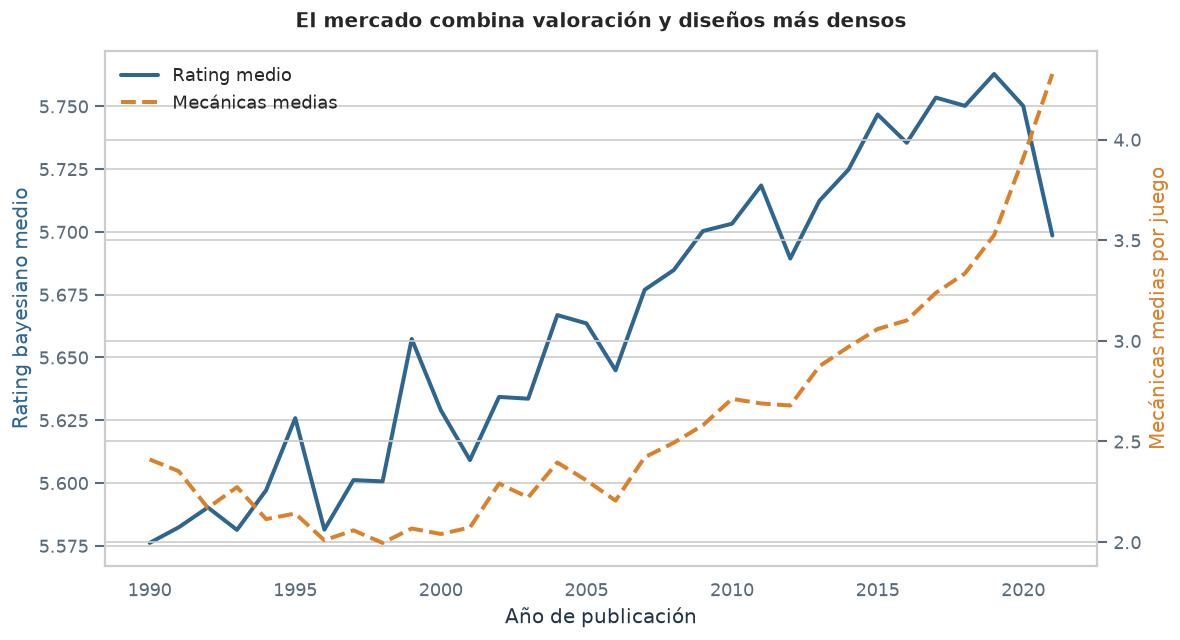

In [8]:
df_moderno = df[df["year_consolidated"].between(1990, 2021)]
figura_evolucion = graficar_evolucion_mercado(df_moderno)
figura_evolucion


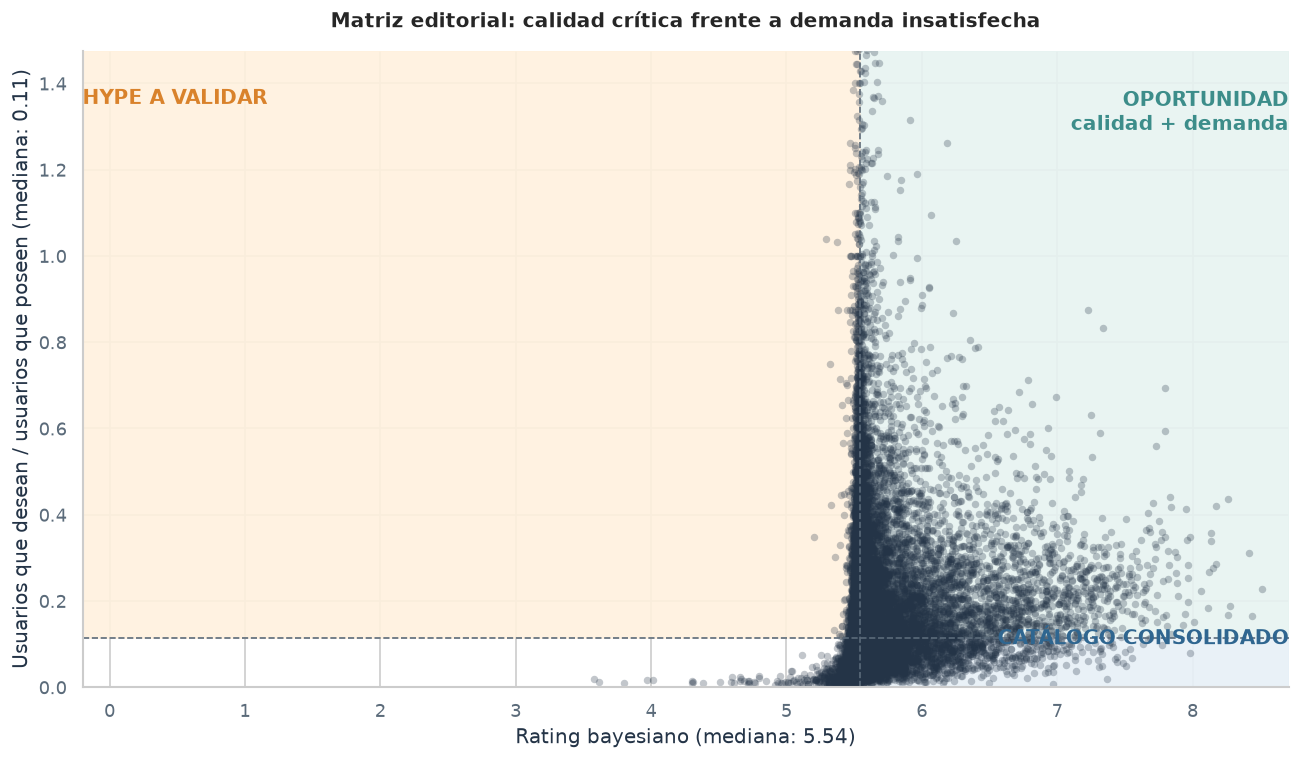

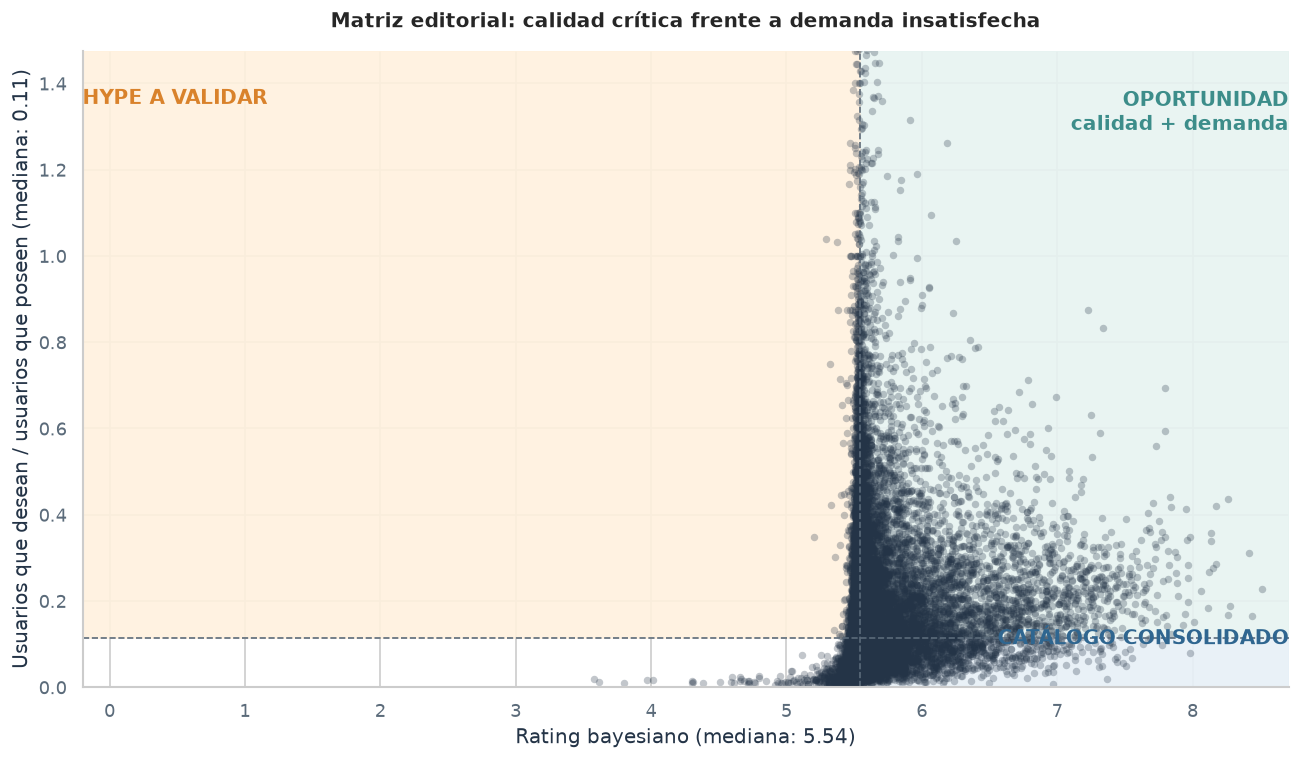

In [9]:
df["tasa_deseo"] = df["wishing"] / (df["owned"] + 1)
figura_oportunidad = graficar_matriz_oportunidad(df)
figura_oportunidad


Número de perfiles elegido por silhouette score: k = 3

Tamaño y características medias de cada perfil:
                juegos  minplayers  maxplayers  playingtime  minage  num_mecanicas  num_categorias
cluster_perfil                                                                                    
0                11644         1.9         4.2         42.3     8.1            2.0             2.2
1                 6434         1.7         4.0        133.6    12.0            4.9             3.3
2                 3397         3.0         8.7         49.7    10.5            2.2             2.8


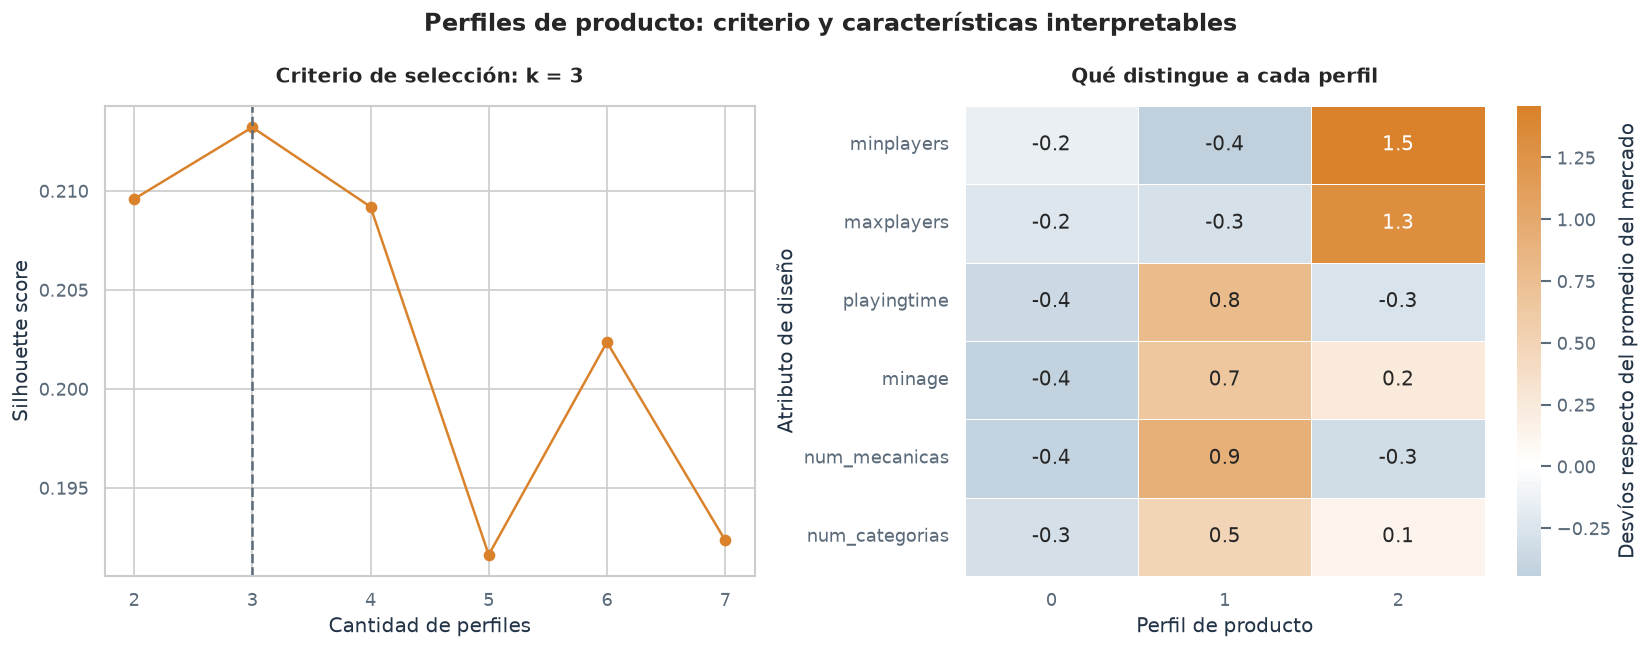

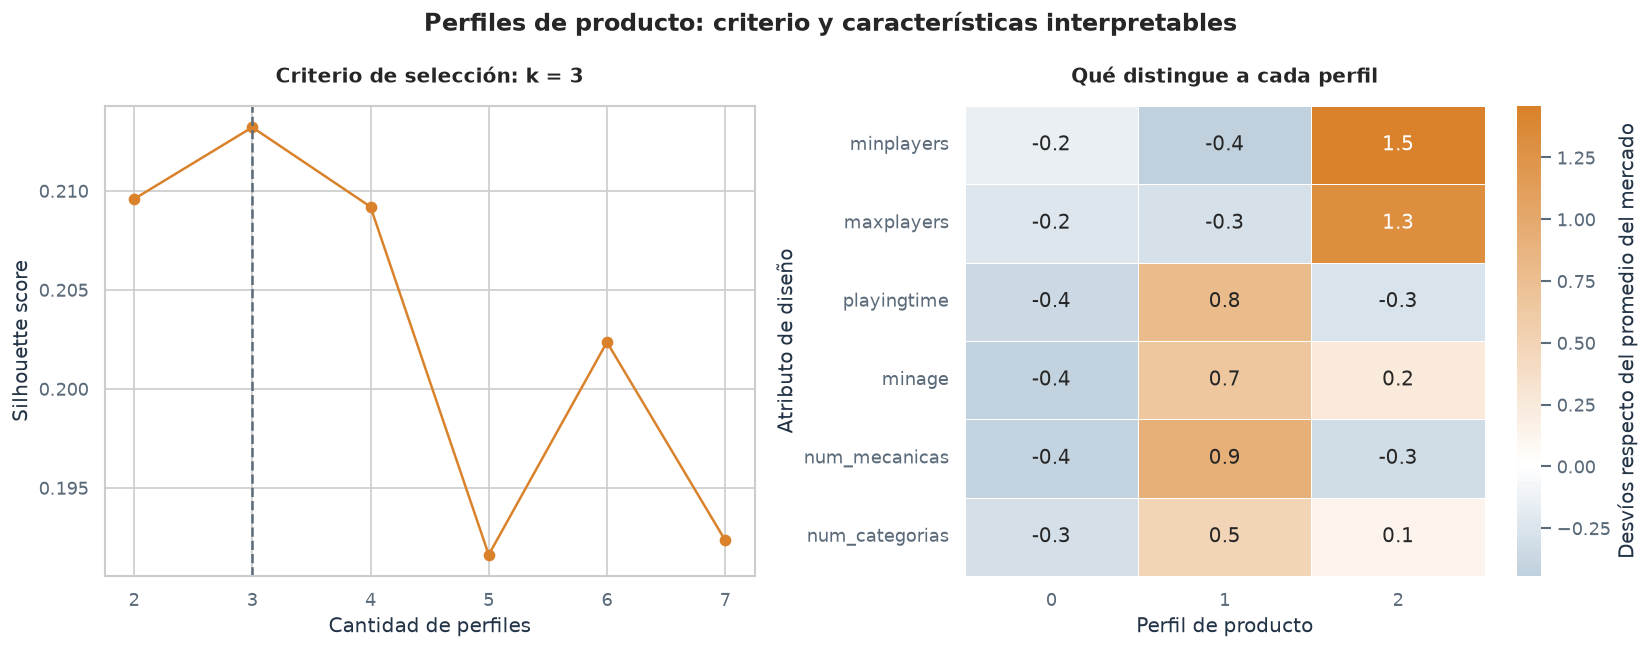

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

cluster_features = [
    "minplayers", "maxplayers", "playingtime", "minage",
    "num_mecanicas", "num_categorias",
]
cluster_matrix = df[cluster_features].apply(pd.to_numeric, errors="coerce")
cluster_matrix = cluster_matrix.fillna(cluster_matrix.median()).fillna(0)
scaler_clusters = StandardScaler()
cluster_scaled = scaler_clusters.fit_transform(cluster_matrix)

cluster_metrics = []
cluster_models = {}
for number_clusters in range(2, 8):
    model = KMeans(n_clusters=number_clusters, random_state=42, n_init=20)
    labels = model.fit_predict(cluster_scaled)
    cluster_metrics.append({
        "k": number_clusters,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(cluster_scaled, labels),
    })
    cluster_models[number_clusters] = model

metricas_clusters = pd.DataFrame(cluster_metrics)
k_optimo = int(metricas_clusters.loc[metricas_clusters["silhouette"].idxmax(), "k"])
modelo_clusters = cluster_models[k_optimo]
df["cluster_perfil"] = modelo_clusters.labels_

perfil_resumen = df.groupby("cluster_perfil")[cluster_features].mean().round(1)
tamanio_perfiles = df["cluster_perfil"].value_counts().sort_index().rename("juegos")
print(f"Número de perfiles elegido por silhouette score: k = {k_optimo}")
print("\nTamaño y características medias de cada perfil:")
print(pd.concat([tamanio_perfiles, perfil_resumen], axis=1).to_string())

perfil_estandarizado = (perfil_resumen - cluster_matrix.mean()) / cluster_matrix.std()
figura_perfiles, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(metricas_clusters["k"], metricas_clusters["silhouette"], marker="o", color=PALETTE["orange"])
axes[0].axvline(k_optimo, linestyle="--", color=PALETTE["muted"])
axes[0].set_title(f"Criterio de selección: k = {k_optimo}")
axes[0].set_xlabel("Cantidad de perfiles")
axes[0].set_ylabel("Silhouette score")

sns.heatmap(
    perfil_estandarizado.T,
    cmap=LinearSegmentedColormap.from_list("profile_scale", [PALETTE["blue"], "white", PALETTE["orange"]]),
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={"label": "Desvíos respecto del promedio del mercado"},
    ax=axes[1],
)
axes[1].set_title("Qué distingue a cada perfil")
axes[1].set_xlabel("Perfil de producto")
axes[1].set_ylabel("Atributo de diseño")
figura_perfiles.suptitle("Perfiles de producto: criterio y características interpretables", weight="bold")
figura_perfiles.tight_layout()
figura_perfiles


## 4.3 Modelado Predictivo: Formulación y Fundamentación de Problemas

Para asistir la toma de decisiones estratégicas de una editorial que evalúa nuevos desarrollos antes de iniciar su producción física, se plantean dos problemas de aprendizaje automático complementarios.

En estricto cumplimiento de las restricciones metodológicas del problema, **ningún modelo utiliza variables posteriores al lanzamiento** (tales como `users_rated`, `owned`, `trading`, `wanting`, `wishing` o `rank`). Estas magnitudes solo existen una vez que el juego ya circula en el mercado y su inclusión constituiría fuga de información (*data leakage*), invalidando la utilidad del modelo para evaluar prototipos inéditos. El espacio de predictoras se restringe exclusivamente a atributos intrínsecos de diseño disponibles en la mesa de desarrollo: cantidad mínima y máxima de jugadores, duración estimada, edad mínima recomendada, densidad de mecánicas y categorías temáticas.

---

### Problema 1: Regresión Continua sobre la Calificación Crítica
* **Variable Objetivo:** `bayes_average` (Calificación bayesiana ponderada, escala 1 a 10).
* **Relevancia del Problema:** La calificación promedio simple (`average`) es vulnerable a la varianza de muestras pequeñas (juegos con pocos votos extremos). BGG computa `bayes_average` incorporando votos *a priori* hacia la media poblacional, lo que la convierte en una métrica robusta de la calidad y recepción crítica del juego. Predecir este valor permite estimar el techo de valoración que el diseño estructural puede aspirar a conseguir.
* **Estrategia de Modelado:** Se compara un modelo nulo de referencia (*Dummy Regressor* basado en la media) contra un modelo lineal regularizado (*Ridge*) y un ensamble de árboles con gradiente (*HistGradientBoostingRegressor*), evaluando la reducción en RMSE, MAE y la varianza explicada ($R^2$).

---

### Problema 2: Clasificación de Éxito Editorial (Top 15% del Mercado)
* **Variable Objetivo:** `es_exito` (Variable binaria: `1` si el juego se ubica en el percentil 85 superior de `bayes_average`; `0` en caso contrario).
* **Relevancia del Problema:** En la práctica editorial, la decisión de negocio no radica en adivinar decimales de calificación, sino en clasificar si un prototipo tiene potencial para ingresar al segmento de títulos destacados que justifican inversiones en arte, moldes de plástico y tiradas masivas de imprenta.
* **Matriz de Costo y Trade-off de Decisión:**
  * **Falso Positivo (Error Tipo I):** Clasificar un juego mediocre como exitoso, enviarlo a producción y sufrir pérdidas directas por inventario inmovilizado y costos de fabricación irrecuperables.
  * **Falso Negativo (Error Tipo II):** Descartar un prototipo viable que habría tenido éxito (costo de oportunidad).
  * *Criterio de negocio:* Para una editorial con presupuesto de capital acotado, el Falso Positivo es financieramente más destructivo que el Falso Negativo. Por ende, el modelo priorizará optimizar la **Precisión** sobre el **Recall**, evaluándose mediante curvas ROC-AUC y Precision-Recall ante el desbalance natural de clases (15% positivos vs. 85% negativos).
* **Estrategia de Modelado:** Comparación de un clasificador base estratificado contra Regresión Logística y *Random Forest Classifier*, garantizando que la separación *Train/Test* (80/20) y la codificación de mecánicas se ejecuten sin contaminación cruzada.

Resultados de regresión
           Modelo  RMSE   MAE     R2
 Baseline (media) 0.358 0.229 -0.000
            Ridge 0.314 0.196  0.230
Gradient boosting 0.303 0.179  0.283

Resultados de clasificación
                Modelo  ROC-AUC  Average precision
Baseline estratificado    0.505              0.152
   Regresión logística    0.810              0.428
         Random Forest    0.831              0.473


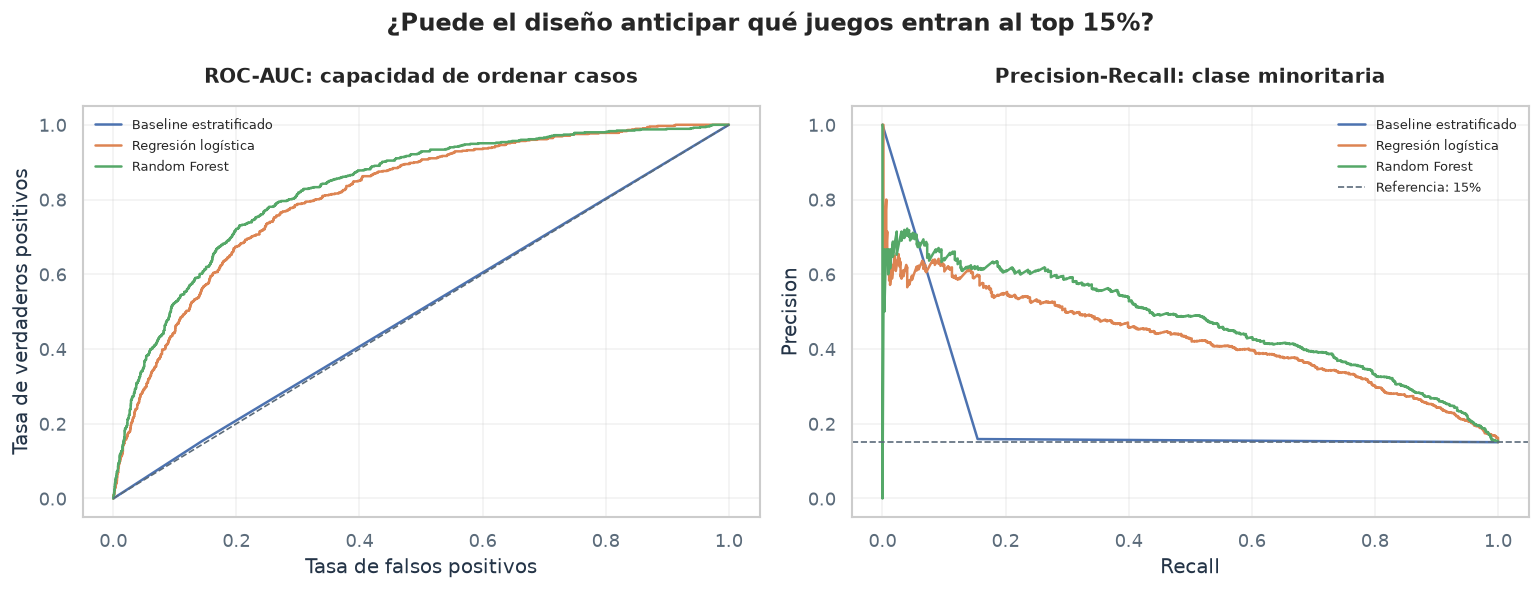

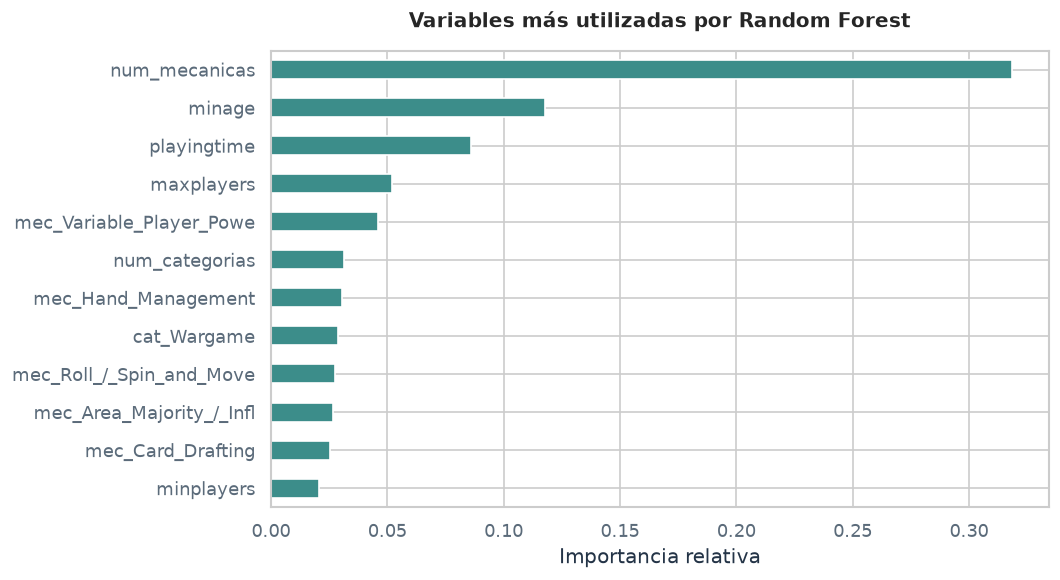

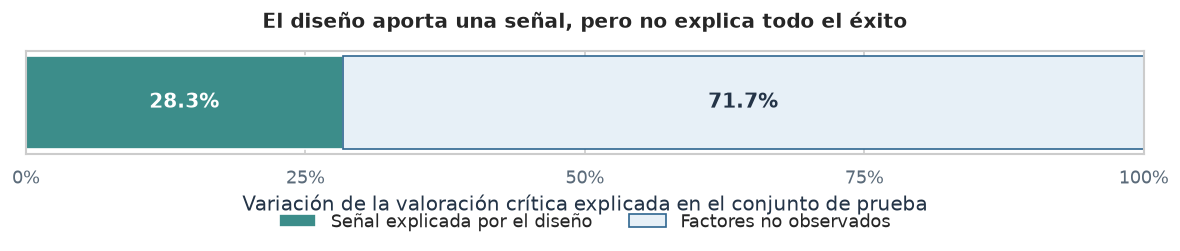

In [11]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    r2_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Solo se utilizan atributos disponibles antes del lanzamiento.
numeric_features = [
    "minplayers", "maxplayers", "playingtime",
    "minage", "num_mecanicas", "num_categorias",
]
target_threshold = df["bayes_average"].quantile(0.85)
df["es_exito"] = (df["bayes_average"] >= target_threshold).astype(int)
model_features = numeric_features + ["boardgamemechanic_parsed", "boardgamecategory_parsed"]
X_base = df[model_features].copy()
y_regression = df["bayes_average"].to_numpy()
y_classification = df["es_exito"].to_numpy()

X_train_raw, X_test_raw, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X_base,
    y_regression,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification,
)

mechanics_train = [item for values in X_train_raw["boardgamemechanic_parsed"] for item in values]
categories_train = [item for values in X_train_raw["boardgamecategory_parsed"] for item in values]
top_mechanics = pd.Series(mechanics_train).value_counts().head(15).index.tolist()
top_categories = pd.Series(categories_train).value_counts().head(10).index.tolist()


def vectorizar_diseno(data):
    """Codifica variables numéricas y vocabularios ajustados solo en train."""
    result = data[numeric_features].apply(pd.to_numeric, errors="coerce")
    result = result.fillna(result.median()).fillna(0)
    for mechanic in top_mechanics:
        result[f"mec_{mechanic.replace(' ', '_')[:20]}"] = data["boardgamemechanic_parsed"].apply(lambda values: int(mechanic in values))
    for category in top_categories:
        result[f"cat_{category.replace(' ', '_')[:20]}"] = data["boardgamecategory_parsed"].apply(lambda values: int(category in values))
    return result


X_train = vectorizar_diseno(X_train_raw)
X_test = vectorizar_diseno(X_test_raw)
scaler_model = StandardScaler()
X_train[numeric_features] = scaler_model.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler_model.transform(X_test[numeric_features])

regression_models = {
    "Baseline (media)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=10.0, random_state=42),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=42, max_iter=150),
}
regression_results = []
for model_name, model in regression_models.items():
    model.fit(X_train, y_reg_train)
    predictions = model.predict(X_test)
    regression_results.append({
        "Modelo": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, predictions)),
        "MAE": mean_absolute_error(y_reg_test, predictions),
        "R2": r2_score(y_reg_test, predictions),
    })
regression_results = pd.DataFrame(regression_results)

classification_models = {
    "Baseline estratificado": DummyClassifier(strategy="stratified", random_state=42),
    "Regresión logística": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1),
}
classification_results = []
roc_precision_figure, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, model in classification_models.items():
    model.fit(X_train, y_clf_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_clf_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_clf_test, probabilities)
    classification_results.append({
        "Modelo": model_name,
        "ROC-AUC": roc_auc_score(y_clf_test, probabilities),
        "Average precision": average_precision_score(y_clf_test, probabilities),
    })
    axes[0].plot(false_positive_rate, true_positive_rate, label=model_name)
    axes[1].plot(recall, precision, label=model_name)

classification_results = pd.DataFrame(classification_results)
positive_rate = y_clf_test.mean()
axes[0].plot([0, 1], [0, 1], "--", color=PALETTE["muted"], linewidth=1)
axes[1].axhline(positive_rate, linestyle="--", color=PALETTE["muted"], linewidth=1, label=f"Referencia: {positive_rate:.0%}")
axes[0].set_title("ROC-AUC: capacidad de ordenar casos")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Precision-Recall: clase minoritaria")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
for axis in axes:
    axis.legend(frameon=False, fontsize=8)
    axis.grid(alpha=0.25)
roc_precision_figure.suptitle("¿Puede el diseño anticipar qué juegos entran al top 15%?", weight="bold")
roc_precision_figure.tight_layout()

random_forest = classification_models["Random Forest"]
feature_importance = pd.Series(random_forest.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(12).sort_values()
importance_figure, importance_axis = plt.subplots(figsize=(9, 5))
feature_importance.plot.barh(ax=importance_axis, color=PALETTE["teal"])
importance_axis.set_title("Variables más utilizadas por Random Forest")
importance_axis.set_xlabel("Importancia relativa")
importance_axis.set_ylabel("")
importance_figure.tight_layout()

r2_gradient_boosting = float(regression_results.loc[regression_results["Modelo"] == "Gradient boosting", "R2"].iloc[0])
executive_figure, executive_axis = plt.subplots(figsize=(10, 2.8))
explained = max(0, min(r2_gradient_boosting, 1))
executive_axis.barh([0], [explained], color=PALETTE["teal"], height=0.42, label="Señal explicada por el diseño")
executive_axis.barh([0], [1 - explained], left=[explained], color=PALETTE["light_blue"], edgecolor=PALETTE["blue"], height=0.42, label="Factores no observados")
executive_axis.text(explained / 2, 0, f"{explained:.1%}", ha="center", va="center", color="white", weight="bold")
executive_axis.text(explained + (1 - explained) / 2, 0, f"{1 - explained:.1%}", ha="center", va="center", color=PALETTE["ink"], weight="bold")
executive_axis.set_xlim(0, 1)
executive_axis.set_yticks([])
executive_axis.set_xticks([0, .25, .5, .75, 1])
executive_axis.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
executive_axis.set_title("El diseño aporta una señal, pero no explica todo el éxito")
executive_axis.set_xlabel("Variación de la valoración crítica explicada en el conjunto de prueba")
executive_axis.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.42), ncol=2)
executive_figure.tight_layout()

print("Resultados de regresión")
print(regression_results.round(3).to_string(index=False))
print("\nResultados de clasificación")
print(classification_results.round(3).to_string(index=False))


## Conclusiones del trabajo

### Qué aprendimos

1. **El diseño aporta una señal, pero no decide solo.**
   El modelo de Gradient Boosting alcanza un $R^2 = 0.276$ y un MAE de 0.179 en el conjunto de prueba. Esto significa que las variables estructurales ayudan a estimar la recepción crítica, pero todavía queda una parte mayoritaria explicada por factores que no están en los datos.
2. **El potencial de entrar al top 15% puede ordenarse mejor que al azar.**
   Random Forest obtiene ROC-AUC = 0.832 y Average Precision = 0.474. Average Precision es especialmente importante porque solo el 15% de los casos pertenece a la clase positiva. El modelo sirve para priorizar prototipos, no para aprobar automáticamente una producción.
3. **La duración y la complejidad representan un trade-off editorial.**
   El gráfico de dispersión muestra cómo los diseños largos y densos conviven con distintos niveles de adopción. Un producto puede ser atractivo para un público experto y, al mismo tiempo, tener una audiencia minoritaria para retail.
4. **Los tópicos describen lenguajes de diseño diferentes.**
   NMF encuentra vocabularios asociados con construcción urbana, guerra, cartas, dados y colocación de losetas. Son agrupaciones exploratorias que ayudan a comparar posicionamientos, no categorías objetivas ni relaciones causales.
5. **La matriz de oportunidad convierte datos en una lista de investigación.**
   La combinación de calificación crítica y demanda relativa puede ayudar a priorizar licencias, localizaciones o reimpresiones. Antes de decidir, hay que sumar precio, derechos, costos, producción, distribución y validación comercial.

### Limitaciones

- BoardGameGeek representa principalmente a aficionados y no a todo el mercado retail.
- La fuente es un corte temporal de enero de 2022.
- El dataset no contiene arte, componentes, precio, marketing, distribución ni resultados financieros.
- Las asociaciones descriptivas no prueban causalidad.
- La importancia de variables de Random Forest es útil para interpretar el modelo, pero no equivale a un efecto causal.

### Recomendación final

Usar el pipeline como un **filtro inicial de decisión**: primero identificar perfiles y nichos prometedores, después validar con investigación de mercado, prototipos, costos y pruebas con público objetivo.